In [ ]:
import json
import pandas as pd

df = pd.read_json('member-publications-data_2025-08-05.json')
df.head()


# 81% are missing a theme
# 17% are not assigned a country
# 71% are not assigned SDGs
# about 300 documents seem to be duplicates (title)
# 86% documents have a download link

,title,agency,link,download-link,type,themes,geo-scope,countries,SDGs,item-ID
0,Action against child trafficking for labour an...,International Labour Organization,https://www.unevaluation.org/member_publicatio...,https://webapps.ilo.org/ievaldiscovery/files/f...,Project/Programme,Children; Conflict,Country,Peru,NA,11673
1,Thematic evaluation on IFAD's support to gende...,International Fund for Agricultural Development,https://www.unevaluation.org/member_publicatio...,https://ioe.ifad.org/en/w/thematic-evaluation-...,Global/Thematic,Gender,NA,NA,NA,13752
2,Terminal Evaluation of the UNEP Project “Secre...,United Nations Environment Programme,https://www.unevaluation.org/member_publicatio...,https://wedocs.unep.org/20.500.11822/47207,Project/Programme,NA,Global,NA,NA,15075
3,Evaluation of WFP's Environmental Policy,World Food Programme,https://www.unevaluation.org/member_publicatio...,https://www.wfp.org/publications/evaluation-wf...,Policy/Strategy,Environment,Global,NA,SDG2 - Zero Hunger,11634
4,Evaluation of Global Health Days 2019-2023,World Health Organization,https://www.unevaluation.org/member_publicatio...,NA,Global/Thematic,Communications and media,Global,NA,SDG3 - Good Health and Well-Being,15542


In [3]:
df['countries'].value_counts()

countries
NA                                                                                                                                                                                                                                                                  2575
United States                                                                                                                                                                                                                                                        292
Bangladesh                                                                                                                                                                                                                                                           234
India                                                                                                                                                                                              

In [ ]:
# not sure we should deduplicate based on title

TypeError: DataFrame.dropna() takes 1 positional argument but 2 were given

In [4]:
df = df[df['download-link'] != "NA"]

In [ ]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
import geodatasets
import pandas as pd


# count countries
country_series = df['countries'].dropna().str.split(';')
country_series = country_series.explode().str.strip() # transform the list in each row into multiple lists

country_counts = country_series.value_counts().reset_index()
country_counts.columns = ['country', 'count']

country_counts['country'] = country_counts['country'].str.strip()

In [7]:
country_counts = country_counts[country_counts['country'] != 'NA']

In [ ]:
# load world map
# URL for Natural Earth low resolution shapefile
url = "https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_countries.zip"

# read the shapefile directly from the URL using geopandas
world = gpd.read_file(url)

#world.plot(figsize=(15, 10), edgecolor='black', color='lightblue')
plt.show()

In [6]:
# find countries in the dataset that cannot be matched to map data

diff = set(country_counts['country']) - set(world['NAME'])
print("In country_counts['country'] but not in world['NAME']:", diff)

#  Grenada
#  Aruba
#  Liechtenstein
#  Bahrain
#  Cayman Islands
#  Malta
#  Virgin Islands (U.S.)
#  Cabo Verde
#  Sao Tome and Principe
#  San Marino
#  Nauru
#  Singapore
#  Maldives
#  St. Vincent and the Grenadines
#  Andorra
#  West Bank and Gaza
#  Marshall Islands
#  Kiribati
#  Barbados
#  Monaco
#  Seychelles
#  Palau
#  Tonga
#  St. Kitts and Nevis
#  Antigua and Barbuda
#  Micronesia, Fed. Sts.
#  Comoros
#  St. Lucia
#  Samoa
#  Tuvalu
#  Swaziland

 # and vice versa:
diff_reverse = set(world['NAME']) - set(country_counts['country'])
print("In world['NAME'] but not in country_counts['country']:", diff_reverse)

 # New Caledonia
 # Puerto Rico
 # N. Cyprus
 # Falkland Is.
 # Somaliland
 # Greenland
 # W. Sahara
 # Taiwan


NameError: name 'world' is not defined

In [ ]:
from thefuzz import process

# Your list of country names
input_countries = [
    "Grenada", "Aruba", "Liechtenstein", "Bahrain", 
    "Cayman Islands", "Malta", "Virgin Islands (U.S.)", "Cabo Verde",
    "Sao Tome and Principe", "San Marino", "Nauru", "Singapore", "Maldives",
    "St. Vincent and the Grenadines", "Andorra", 
    "West Bank and Gaza", "Marshall Islands", "Kiribati", "Turkiye", "Barbados", "Monaco",
    "Seychelles", "Palau", "Tonga", "St. Kitts and Nevis", ,
    "Antigua and Barbuda", "Micronesia, Fed. Sts.", "Comoros", "St. Lucia", "Samoa",
    "Tuvalu", "Swaziland"
]

# Assuming world['NAME'] contains the standard country names
world_names = world['NAME'].unique()

# Match each country
matches = {}
for country in input_countries:
    match, score = process.extractOne(country, world_names)
    matches[country] = (match, score)

# Print results
for orig, (best_match, score) in matches.items():
    print(f"{orig:<35} → {best_match:<35} (score: {score})")

In [ ]:
# fix name mismatches
country_name_corrections = {
 "Venezuela, RB": "Venezuela",
 "Congo, Dem. Rep." : "Dem. Rep. Congo",
 "Dominica" : "Dominican Rep.",
 "Dominican Republic" : "Dominican Rep.",
 "Eswatini" : "eSwatini",
 "United States": "United States of America",
 "Slovak Republic" : "Slovakia",
 "Congo, Rep." : "Dem. Rep. Congo",
 "Iran, Islamic Rep." : "Iran",
 "Korea, Dem. People's Rep." : "North Korea",
 "Central African Republic" : "Central African Rep.",
 "Viet Nam" : "Vietnam",
 "Korea, Rep." : "South Korea",
 "Cote d'Ivoire" : "Côte d'Ivoire",
 "Yemen, Rep." : "Yemen",
 "Russian Federation" : "Russia",
 "Syrian Arab Republic" : "Syria",
 "Egypt, Arab Rep." : "Egypt",
 "Lao PDR" : "Laos",
 "South Sudan" : "S. Sudan",
 "Bosnia and Herzegovina" : "Bosnia and Herz.",
 "Brunei Darussalam" : "Brunei",
 "Bahamas, The" : "Bahamas",
 "Gambia, The" : "Gambia",
 "Mauritius" : "Mauritania",
 "Solomon Islands" : "Solomon Is.",
 "Equatorial Guinea" : "Eq. Guinea",
 "Turkiye" : "Turkey"
} 

# the way we do this currently is if the country is mentioned 

country_counts['country'] = country_counts['country'].replace(country_name_corrections)

# merge with world map
world = world.merge(country_counts, how='left', left_on='NAME', right_on='country')
world['count'] = world['count'].fillna(0)
print(world['count'].value_counts().sum())

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

# example custom bins: adjust as needed
bins = [0, 1, 5, 10, 25, 50, 100, 200, world['count'].max()]

# set up a plot
drop_idxs = world["CONTINENT"].isin(["Antarctica", "Seven seas (open ocean)"])
world = world.drop(world[drop_idxs].index)

fig, ax = plt.subplots(figsize=(15, 10))
world.plot(
    ax=ax,
    column='count',
    cmap='Greens',
    linewidth=0.5,
    edgecolor='black',
    legend=True,
    scheme='user_defined',
    classification_kwds={'bins': bins}
)

leg = ax.get_legend()
if leg and hasattr(leg, 'get_texts'):
    for t in leg.get_texts():
      
        try:
            
            label = t.get_text()
            nums = label.replace('(', '').replace(']', '').split(',')
            low = int(float(nums[0]))
            high = int(float(nums[1]))
            t.set_text(f"{low} - {high}")
        except Exception as e:
            pass

# turn off axis ticks
ax.set_xticks([])
ax.set_yticks([])

plt.title("Countries mentioned in member publications", fontsize=16)
plt.show()

In [ ]:
### TO-DOs ###

# adjust colours, font size and dimensions
# check which countries could not be matched
# add countries geoparsed from text
# add country x SDG visualisation (think of good ways to do that)

In [8]:
# break up the SDGs column by ";" and count mentions of each SDG

SDG_series = df['SDGs'].dropna().str.split(';')
SDG_series = SDG_series.explode().str.strip() # transform the list in each row into multiple lists

SDG_counts = SDG_series.value_counts().reset_index()
SDG_counts.columns = ['SDG', 'count']
SDG_counts = SDG_counts[SDG_counts['SDG'] != 'NA']

C:\Users\dand\AppData\Local\Temp\ipykernel_13724\2600648994.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=SDG_counts, y="SDG", x="count", palette=palette, alpha = 1)


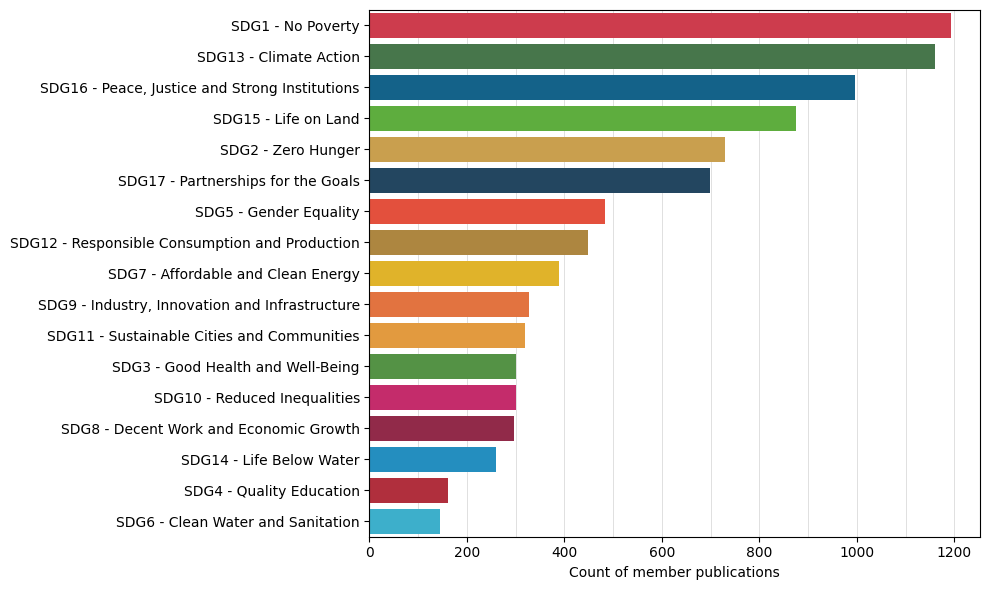

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sdg_colours = {
    "SDG1 - No Poverty": "#E5243B",
    "SDG2 - Zero Hunger": "#DDA63A",
    "SDG3 - Good Health and Well-Being": "#4C9F38",
    "SDG4 - Quality Education": "#C5192D",
    "SDG5 - Gender Equality": "#FF3A21",
    "SDG6 - Clean Water and Sanitation": "#26BDE2",
    "SDG7 - Affordable and Clean Energy": "#FFC30B",
    "SDG8 - Decent Work and Economic Growth": "#A21942",
    "SDG9 - Industry, Innovation and Infrastructure": "#FD6925",
    "SDG10 - Reduced Inequalities": "#DD1367",
    "SDG11 - Sustainable Cities and Communities": "#FD9D24",
    "SDG12 - Responsible Consumption and Production": "#BF8b2E",
    "SDG13 - Climate Action": "#3F7E44",
    "SDG14 - Life Below Water": "#0A97D9",
    "SDG15 - Life on Land": "#56C02B",
    "SDG16 - Peace, Justice and Strong Institutions": "#00689D",
    "SDG17 - Partnerships for the Goals": "#19486A"
}

# create palette from the SDG column
palette = [sdg_colours.get(sdg, "#cccccc") for sdg in SDG_counts["SDG"]]

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=SDG_counts, y="SDG", x="count", palette=palette, alpha = 1)

max_val = SDG_counts["count"].max()

for x in range(100, int(max_val) + 100, 100):
    ax.axvline(x=x, color='lightgrey', linewidth=0.5, zorder=0)

# xticks = np.arange(0, max_val + 100, 250)
# ax.set_xticks(xticks)
ax.set(ylabel=None)
ax.set(xlabel="Count of member publications")

plt.tight_layout()
plt.show()

# we could make a similar graph including our annotation counts for SDGs in % with different alphas

In [16]:
df_sdg = df[df['SDGs'] != 'NA']

x = df_sdg.shape[0]

random_indices = np.random.randint(0,x,size=100)

In [25]:
df_random = df_sdg.iloc[random_indices]
df_random.to_csv("SDG-random.csv")